# Medicine Batch Expiry-Risk Prediction & FEFO Prioritization
## Algions AI Labs Assessment: Decision-Support Optimization

### 1. Problem Formulation & Business Risk Engine
Pharmaceutical inventory carries significant financial and clinical risk:
- Expired stock causes direct fiscal write-offs.
- Dispensing expired medication poses serious patient safety hazards and regulatory penalties.

We formulate a dual-layered strategy:
1. **Deterministic Inventory Velocity Engine**: Calculates remaining days $T_{exp} - T_{today}$, historical sales velocity, expected sales before expiry, estimated unsold quantity, and dollar inventory value-at-risk.
2. **Machine Learning Classifier**: Multi-class classifier (Low Risk, Medium Risk, High Risk) trained on batch attributes (quantity, velocity, variability, shelf-life).

$$\text{Expected Demand Before Expiry} = \text{Average Daily Demand} \times \text{Days Remaining}$$
$$\text{Estimated Unsold Quantity} = \max(0, \text{Remaining Quantity} - \text{Expected Demand})$$
$$\text{Inventory Value at Risk} = \text{Estimated Unsold Quantity} \times \text{Purchase Price}$$


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Load classification metrics
with open('../saved_models/expiry_metrics.json', 'r') as f:
    metrics = json.load(f)

df_results = pd.DataFrame(metrics).T
df_results[['accuracy', 'precision', 'recall', 'f1_score', 'high_risk_recall']]

,accuracy,precision,recall,f1_score,high_risk_recall
Decision_Tree,0.975,0.9716,0.975,0.9722,0.7576
Random_Forest,0.967,0.9625,0.967,0.9624,0.4848
XGBoost,0.986,0.9849,0.986,0.9848,0.8485


### 2. Confusion Matrix & High-Risk Batch Recall
In medicine stock control, **High-Risk Batch Recall** is of paramount importance: missing an expiring batch leads to product wastage or illegal dispensing.


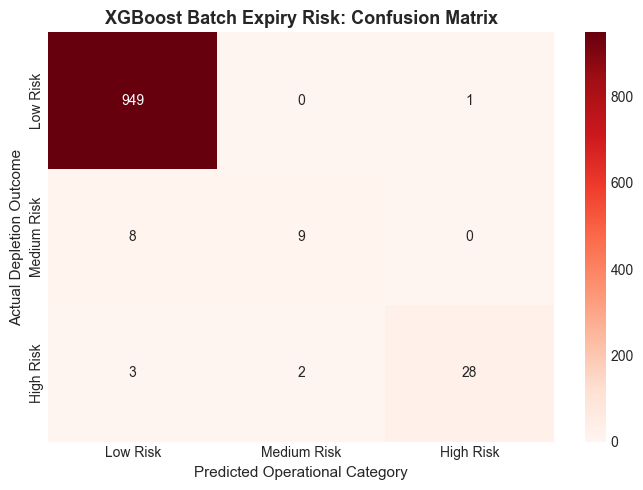

In [2]:
labels = ['Low Risk', 'Medium Risk', 'High Risk']
cm = np.array(metrics['XGBoost']['confusion_matrix'])

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=labels, yticklabels=labels)
plt.title('XGBoost Batch Expiry Risk: Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Operational Category', fontsize=11)
plt.ylabel('Actual Depletion Outcome', fontsize=11)
plt.tight_layout()
plt.show()

### 3. First-Expiry, First-Out (FEFO) Recommendation Logic
Demonstrating batch allocation order when dispensing medication. Expiring lots are liquidated first before opening newer long-dated stock.


In [3]:
from datetime import datetime, timedelta
import sys
sys.path.append('../..')
from ml.expiry_prediction.risk_engine import ExpiryRiskEngine

today = datetime(2026, 11, 15)
batches = [
    {'batch': 'BN-26-8801', 'qty': 65, 'exp': '2026-12-07', 'price': 12.5, 'vel': 2.5},
    {'batch': 'BN-26-8802', 'qty': 120, 'exp': '2027-01-09', 'price': 12.5, 'vel': 2.5},
    {'batch': 'BN-26-9901', 'qty': 200, 'exp': '2028-01-11', 'price': 12.5, 'vel': 2.5}
]

eval_records = []
for b in batches:
    res = ExpiryRiskEngine.calculate_batch_risk(
        quantity_remaining=b['qty'],
        purchase_price=b['price'],
        expiry_date_str=b['exp'],
        average_daily_sales=b['vel'],
        reference_date=today
    )
    res['batch_number'] = b['batch']
    eval_records.append(res)

df_fefo = pd.DataFrame(eval_records)
df_fefo[['batch_number', 'days_until_expiry', 'risk_level', 'estimated_unsold_quantity', 'inventory_value_at_risk', 'recommended_action']]

,batch_number,days_until_expiry,risk_level,estimated_unsold_quantity,inventory_value_at_risk,recommended_action
0,BN-26-8801,22,Medium Risk,10.0,125.0,Monitor dispensing velocity. Prioritize in FEF...
1,BN-26-8802,55,Medium Risk,0.0,0.0,Monitor dispensing velocity. Prioritize in FEF...
2,BN-26-9901,422,Low Risk,0.0,0.0,Optimal turnover: Expected sales comfortably e...


### 4. Decision-Support & Clinical Advisory Statement
> **ADVISORY NOTICE**: The batch risk predictions, suggested stock rotation order, and FEFO alerts generated by this platform are exclusively **operational decision-support guidance** for inventory management. Under no circumstances should these predictions be construed as clinical diagnosis, medical advice, or therapeutic recommendations.